# Project 1: heart attack risk from BRFSS 2015

Predict MICHD (`-1` / `+1`) with a NumPy pipeline. No pandas or sklearn.

1. EDA
2. Preprocessing: survey/leak drop, one hot levels, MI top (`src/preprocessing.py`)
3. Models and 5 fold CV
4. Submission via `python run.py`


## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

import src.eda as eda
import src.experiments as experiments
import src.model as model
import src.preprocessing as prep
from helpers import load_csv_data
from implementations import logistic_regression, ridge_regression

np.random.seed(42)
data = "data/dataset"
cfg = experiments.read_json(experiments.CONFIG_PATH)
prep.ensure_header()


(('_STATE',
  'FMONTH',
  'IDATE',
  'IMONTH',
  'IDAY',
  'IYEAR',
  'DISPCODE',
  'SEQNO',
  '_PSU',
  'CTELENUM',
  'PVTRESD1',
  'COLGHOUS',
  'STATERES',
  'CELLFON3',
  'LADULT',
  'NUMADULT',
  'NUMMEN',
  'NUMWOMEN',
  'CTELNUM1',
  'CELLFON2',
  'CADULT',
  'PVTRESD2',
  'CCLGHOUS',
  'CSTATE',
  'LANDLINE',
  'HHADULT',
  'GENHLTH',
  'PHYSHLTH',
  'MENTHLTH',
  'POORHLTH',
  'HLTHPLN1',
  'PERSDOC2',
  'MEDCOST',
  'CHECKUP1',
  'BPHIGH4',
  'BPMEDS',
  'BLOODCHO',
  'CHOLCHK',
  'TOLDHI2',
  'CVDSTRK3',
  'ASTHMA3',
  'ASTHNOW',
  'CHCSCNCR',
  'CHCOCNCR',
  'CHCCOPD1',
  'HAVARTH3',
  'ADDEPEV2',
  'CHCKIDNY',
  'DIABETE3',
  'DIABAGE2',
  'SEX',
  'MARITAL',
  'EDUCA',
  'RENTHOM1',
  'NUMHHOL2',
  'NUMPHON2',
  'CPDEMO1',
  'VETERAN3',
  'EMPLOY1',
  'CHILDREN',
  'INCOME2',
  'INTERNET',
  'WEIGHT2',
  'HEIGHT3',
  'PREGNANT',
  'QLACTLM2',
  'USEEQUIP',
  'BLIND',
  'DECIDE',
  'DIFFWALK',
  'DIFFDRES',
  'DIFFALON',
  'SMOKE100',
  'SMOKDAY2',
  'STOPSMK2',
  'LASTSMK

## Load data

`load_csv_data` returns train/test matrices, labels, and ids. Positive class is MICHD (`y = 1`).


In [2]:
x_train, x_test, y_train, ids_train, ids_test = load_csv_data(data)
proportions = eda.class_proportions(y_train)
print(f"train X {x_train.shape}, test X {x_test.shape}, train y {y_train.shape}")
print(f"class proportions: {proportions}")


train X (328135, 321), test X (109379, 321), train y (328135,)
class proportions: {-1: 0.911697929205967, 1: 0.08830207079403295}


Train has 328135 rows × 321 features; test has 109379 rows with the same width. The positive MICHD rate is only 8.8%, so a majority classifier would already score about 91% accuracy and an F1 of 0. F1 is the score used to choose a model and a decision cut. Accuracy is reported beside it.


## 1. Exploratory data analysis

### 1a. Data diagnostics

Missing entries are IEEE `NaN` (empty CSV cells). Before transforming anything we:
- measure overall and per column missingness (train vs test)
- list constant columns (zero information)
- classify columns as constant / binary / ordinal / continuous
- plot class counts and per column missing rates


NaNs train: 47175779/105331335 (44.8%), cols with NaN: 239/321
NaNs test:  15724379/35110659 (44.8%), cols with NaN: 232/321
constant cols: 6/321, indices: [ 9 11 12 18 19 22]
kinds: {'constant': 6, 'binary': 14, 'ordinal': 221, 'continuous': 80, 'quasi_constant': 6}
cols with >50% missing: 147


<Axes: title={'center': 'Missing rate by column (train)'}>

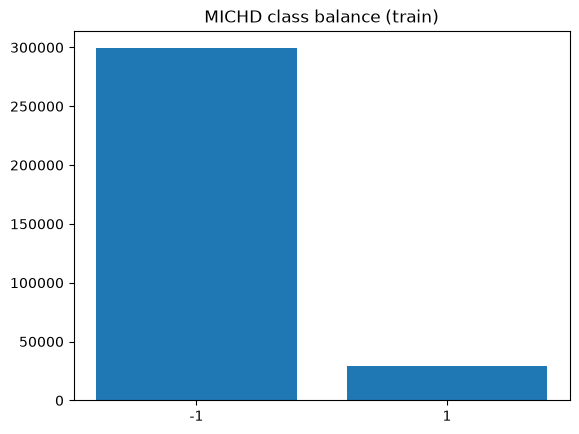

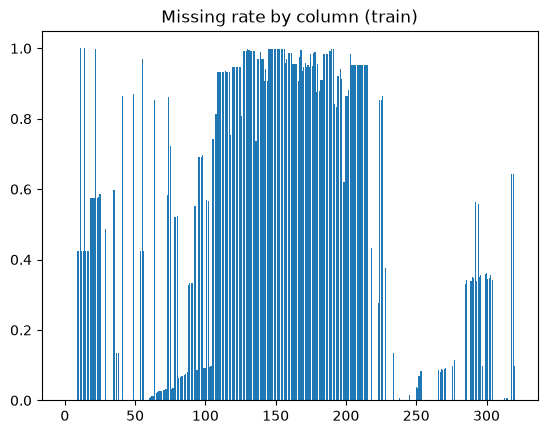

In [3]:
n, d = x_train.shape
miss = eda.missing_count(x_train)
rates = eda.missing_rate(x_train)
drop = eda.constant_mask(x_train)
kinds = eda.classify_columns(x_train)

print(
    f"NaNs train: {miss.sum()}/{n * d} ({100 * miss.sum() / (n * d):.1f}%), "
    f"cols with NaN: {(miss > 0).sum()}/{d}"
)
miss_te = eda.missing_count(x_test)
n_te = x_test.shape[0]
print(
    f"NaNs test:  {miss_te.sum()}/{n_te * d} ({100 * miss_te.sum() / (n_te * d):.1f}%), "
    f"cols with NaN: {(miss_te > 0).sum()}/{d}"
)
print(f"constant cols: {int(drop.sum())}/{d}, indices: {np.flatnonzero(drop)}")
print("kinds:", {k: int(v.sum()) for k, v in kinds.items()})
print("cols with >50% missing:", int((rates > 0.5).sum()))

eda.plot_class_balance(y_train, title="MICHD class balance (train)")
eda.plot_missing_rates(rates, title="Missing rate by column (train)")


About 44.8% of train and test entries are NaN, with a similar column footprint (239 vs 232 columns touched). There is no obvious train vs test missingness shift. Six columns are constant (`[9, 11, 12, 18, 19, 22]`). Most features are ordinal (221), with 80 continuous and 14 binary. 147 columns exceed 50% missing and dominate the sparse bar chart.


### 1b. Missing rate

About 45% of cells are empty. A 50% missing cut would drop 147 columns and keep 174.
The submitted pipeline does not drop them. Missing becomes its own one hot level,
so a skipped module is still visible to the model.

The next cell looks at a few high missing columns. The cell after that plots how
many columns would survive as the missing cut moves.


cols with >50% missing: 147 e.g. [11 14 18 19 20 21 22 23 24 25 35 41 49 55 64]


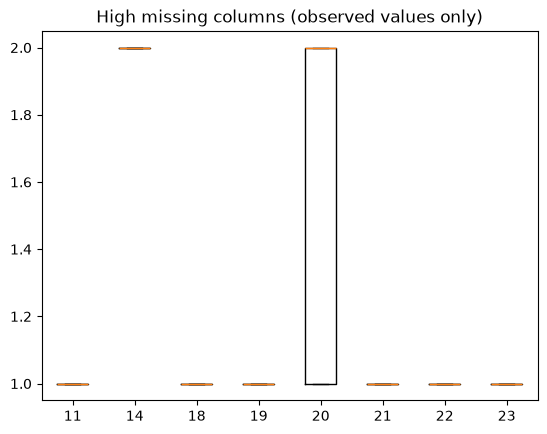

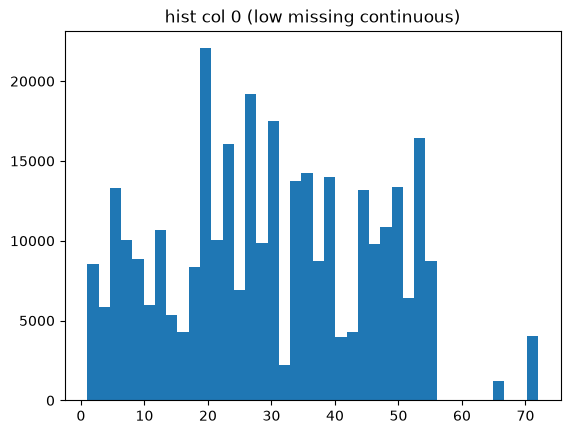

In [4]:
rate_miss = 0.5
hi_miss = np.flatnonzero(rates > rate_miss)
print(f"cols with >{rate_miss*100:g}% missing: {hi_miss.size} e.g. {hi_miss[:15]}")

eda.plot_feature_boxplots(
    x_train, hi_miss[:8], title="High missing columns (observed values only)"
)

cand = np.flatnonzero(kinds["continuous"] & (rates < 0.3) & (~drop))
col = int(cand[0])
plt.figure()
plt.hist(x_train[:, col][np.isfinite(x_train[:, col])], bins=40)
plt.title(f"hist col {col} (low missing continuous)")
plt.show()


High missing columns still show structure on the observed slice, but most rows
are blank. Treating the blank as a level keeps that skip pattern instead of filling
it with a made up value.


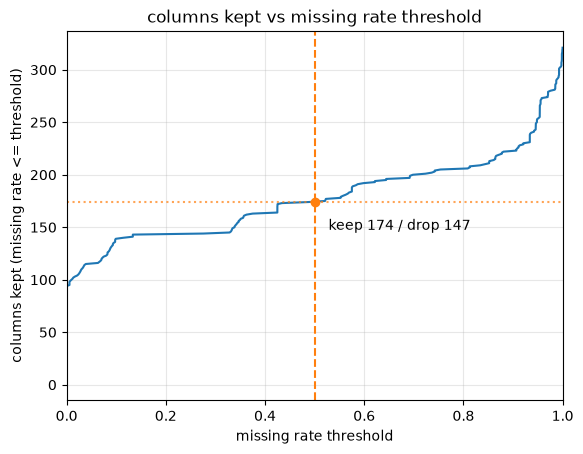

at rate_miss=0.5: 174 kept, 147 dropped


In [5]:
n_keep = int((rates <= rate_miss).sum())
n_drop = int((rates > rate_miss).sum())
sorted_rates = np.sort(rates)

fig, ax = plt.subplots()
ax.plot(sorted_rates, np.arange(1, len(sorted_rates) + 1))
ax.axvline(rate_miss, color="C1", linestyle="--")
ax.axhline(n_keep, color="C1", linestyle=":", alpha=0.7)
ax.scatter([rate_miss], [n_keep], color="C1", zorder=3)
ax.annotate(
    f"keep {n_keep} / drop {n_drop}",
    xy=(rate_miss, n_keep),
    xytext=(10, -20),
    textcoords="offset points",
)
ax.set_xlabel("missing rate threshold")
ax.set_ylabel("columns kept (missing rate <= threshold)")
ax.set_title("columns kept vs missing rate threshold")
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
plt.show()
print(f"at rate_miss={rate_miss}: {n_keep} kept, {n_drop} dropped")


At a 50% missing cut the curve would keep 174 columns and drop 147. The model
does not use that cut. It keeps every non survey, non leak column that has at least
one finite value on the training rows, then encodes missing as a level.


### 1c. Relation to the MICHD label

Two checks that matter for medical data:

1. **Missingness by class.** Scatter missing rate in class `-1` vs class `1`. Points on `y = x` mean missingness is shared. Points far off the diagonal mean missingness itself may be informative (not a bug: consider a missing indicator later).
2. **Standardized mean gap.** For low missing continuous or ordinal columns, `(mean_1 - mean_-1) / std` ranks which features separate the classes on a comparable scale.


cols with |missing gap| > 5%: 87/321, max gap=0.37
top |standardized mean gap|:
  col  26  GENHLTH  +0.861
  col 248  _AGE80  +0.791
  col 246  _AGEG5YR  +0.772
  col  58  EMPLOY1  +0.730
  col 249  _AGE_G  +0.729


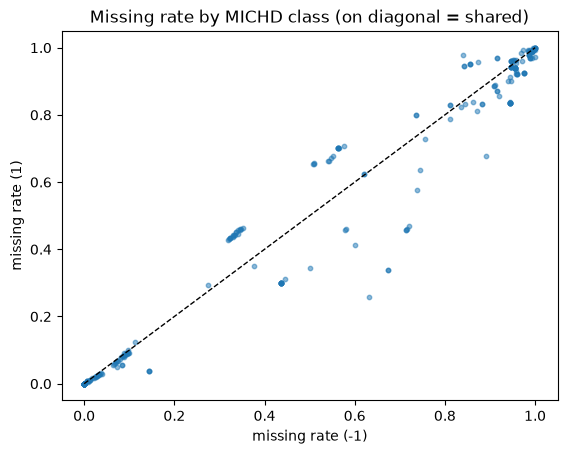

In [6]:
rates_by_y = eda.missing_rate_by_class(x_train, y_train)
r_neg, r_pos = rates_by_y[-1], rates_by_y[1]
eda.plot_missing_rate_by_class(
    r_neg, r_pos, title="Missing rate by MICHD class (on diagonal = shared)"
)
miss_gap = np.abs(r_pos - r_neg)
print(
    f"cols with |missing gap| > 5%: {(miss_gap > 0.05).sum()}/{len(miss_gap)}, "
    f"max gap={miss_gap.max():.2f}"
)

cols, gaps = eda.mean_diff_by_class(
    x_train, y_train, col_mask=kinds["continuous"] | kinds["ordinal"]
)
top = np.argsort(np.abs(gaps))[::-1][:5]
print("top |standardized mean gap|:")
for j, g in zip(cols[top], gaps[top]):
    print(f"  col {int(j):3d}  {prep.HEADER[int(j)]}  {g:+.3f}")

Missing rates mostly follow the diagonal: most NaNs are shared across classes.
A few columns differ by more than 5%, which is why a missing level can help.
The strongest raw mean gaps on low missing columns are reported in the cell above.
Those columns survive as one hot levels if they rank high on mutual information.


### 1d. Age, sex, and smoking vs MICHD

MICHD rate by age group, by sex, and by smoker status, plus age density inside each class.
`_AGEG5YR` codes 1 to 13 are five year bands from 18 up to 80+. `_SMOKER3`: 1 daily, 2 some days, 3 former, 4 never.


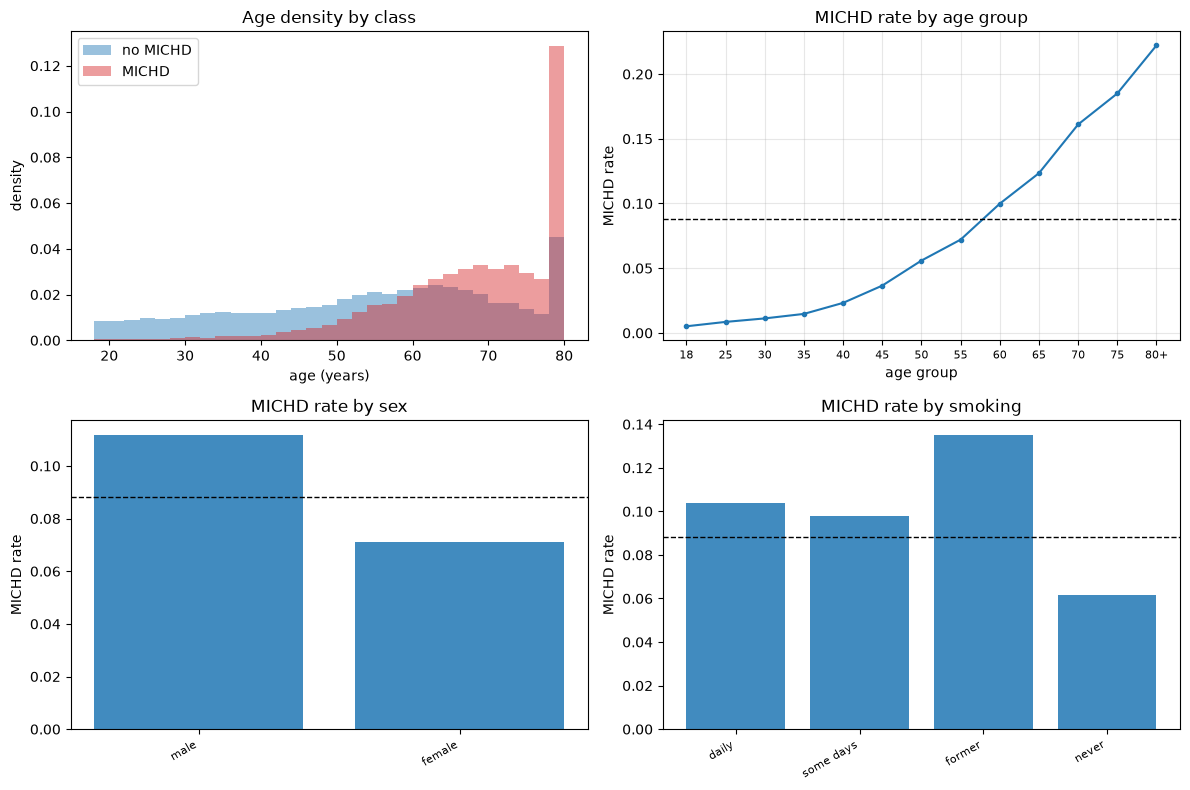

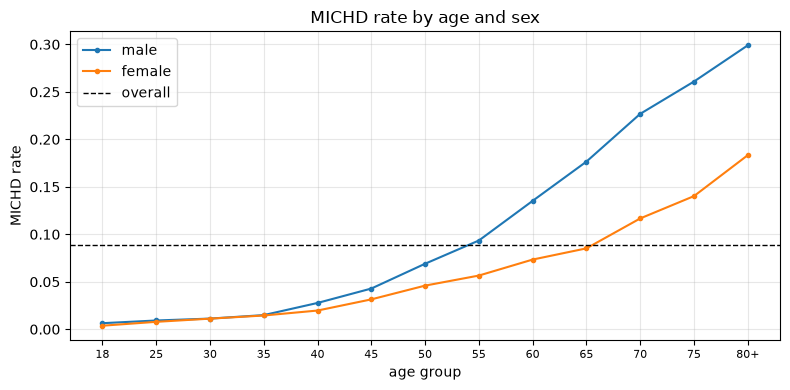

overall MICHD rate 0.088
male 0.112, female 0.071
age 18 to 24 0.005, age 80+ 0.222


In [7]:
age = x_train[:, prep.INDEX["_AGE80"]]
age_g = x_train[:, prep.INDEX["_AGEG5YR"]]
sex = x_train[:, prep.INDEX["SEX"]]
smoke = x_train[:, prep.INDEX["_SMOKER3"]]
overall = float(np.mean(y_train == 1))

age_codes = np.arange(1, 14)
age_labels = ["18", "25", "30", "35", "40", "45", "50", "55", "60", "65", "70", "75", "80+"]
age_rates = eda.michd_rate(y_train, [age_g == c for c in age_codes])
sex_rates = eda.michd_rate(y_train, [sex == 1, sex == 2])
smoke_codes = [1, 2, 3, 4]
smoke_labels = ["daily", "some days", "former", "never"]
smoke_rates = eda.michd_rate(y_train, [smoke == c for c in smoke_codes])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
eda.plot_hist_by_class(axes[0, 0], age, y_train, bins=np.arange(18, 82, 2),
                       title="Age density by class", xlabel="age (years)")
eda.plot_rate_line(axes[0, 1], age_codes, age_rates, "MICHD rate by age group", overall=overall)
axes[0, 1].set_xticks(age_codes)
axes[0, 1].set_xticklabels(age_labels, fontsize=8)
axes[0, 1].set_xlabel("age group")

eda.plot_rate_bars(axes[1, 0], ["male", "female"], sex_rates, "MICHD rate by sex", overall=overall)
eda.plot_rate_bars(axes[1, 1], smoke_labels, smoke_rates, "MICHD rate by smoking", overall=overall)
plt.tight_layout()
plt.show()

# MICHD rate by age, split by sex (line plot)
fig, ax = plt.subplots(figsize=(8, 4))
for label, code in (("male", 1), ("female", 2)):
    rates = eda.michd_rate(y_train, [(age_g == g) & (sex == code) for g in age_codes])
    eda.plot_rate_line(ax, age_codes, rates, "MICHD rate by age and sex", label=label)
ax.axhline(overall, color="k", linestyle="--", lw=1, label="overall")
ax.set_xticks(age_codes)
ax.set_xticklabels(age_labels, fontsize=8)
ax.set_xlabel("age group")
ax.legend()
plt.tight_layout()
plt.show()

print(f"overall MICHD rate {overall:.3f}")
print(f"male {sex_rates[0]:.3f}, female {sex_rates[1]:.3f}")
print(f"age 18 to 24 {age_rates[0]:.3f}, age 80+ {age_rates[-1]:.3f}")


MICHD rises sharply with age. Men have a higher rate than women at most ages.
Former smokers sit above never smokers; daily smoking is less separated once age is ignored,
because younger respondents smoke more and have less disease.


## 2. Preprocessing

All steps live in `src/preprocessing.py`. Fit on training rows only.

1. Drop survey machinery and label leaks.
2. Turn each remaining column into one hot levels (frequent values, quantile bins, missing).
3. Keep the `top_onehot` levels with the highest mutual information with the label.
4. Standardize. `apply` reuses the fitted levels, selection, and scales.


In [8]:
print(f"survey columns dropped: {len(prep.SURVEY_COLUMNS)}")
print(f"leak columns dropped: {prep.LEAK_COLUMNS}")
for name in prep.LEAK_COLUMNS:
    column = x_train[:, prep.INDEX[name]]
    answered = np.isfinite(column)
    print(
        f"  {name:9s} missing {1 - answered.mean():.3f}, "
        f"positive when answered {(y_train[answered] == 1).mean():.3f}"
    )


survey columns dropped: 40
leak columns dropped: ('HAREHAB1', 'STREHAB1', 'CVDASPRN', 'ASPUNSAF')
  HAREHAB1  missing 0.998, positive when answered 1.000
  STREHAB1  missing 0.998, positive when answered 0.358
  CVDASPRN  missing 0.957, positive when answered 0.094
  ASPUNSAF  missing 0.970, positive when answered 0.045


### Fit and apply


In [9]:
y01 = (y_train == 1).astype(float)
rng = np.random.default_rng(42)
fit_idx, val_idx = prep.stratified_split(y01, 0.2, rng)
data_prep = prep.make_data(x_train, cfg)
state, x_fit = prep.fit(data_prep, fit_idx, y_train[fit_idx] == 1, cfg)
x_val = prep.apply(data_prep, val_idx, state)
data_test = dict(data_prep)
data_test["x"] = x_test
x_test_prep = prep.apply(data_test, np.arange(x_test.shape[0]), state)

assert x_fit.shape[1] == cfg["top_onehot"]
assert x_val.shape[1] == x_fit.shape[1] == x_test_prep.shape[1]
print("shapes fit/val/test:", x_fit.shape, x_val.shape, x_test_prep.shape)
print("positive rate fit/val:", y01[fit_idx].mean(), y01[val_idx].mean())


shapes fit/val/test: (262508, 300) (65627, 300) (109379, 300)
positive rate fit/val: 0.08830207079403295 0.08830207079403295


Levels, the mutual information ranking, and the scales come from the fit rows only.


### Selected feature distribution

After `fit`, the 300 kept levels are not spread evenly across the survey.
The left plot counts how many levels come from each raw column (top 20).
The right plot is the mutual information of those 300 levels with MICHD.
Below, the share of fit rows where each level is on (before standardization), sorted.


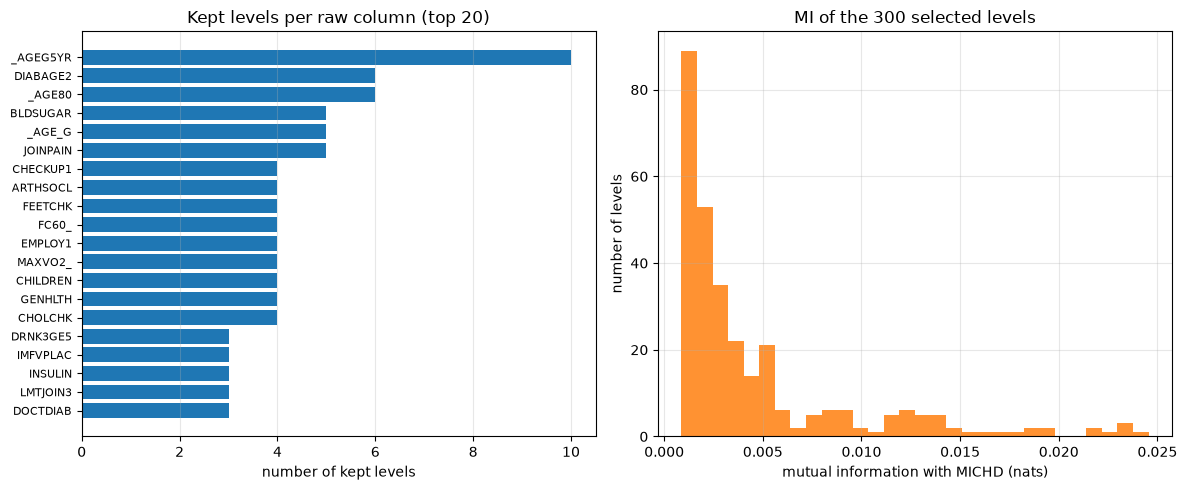

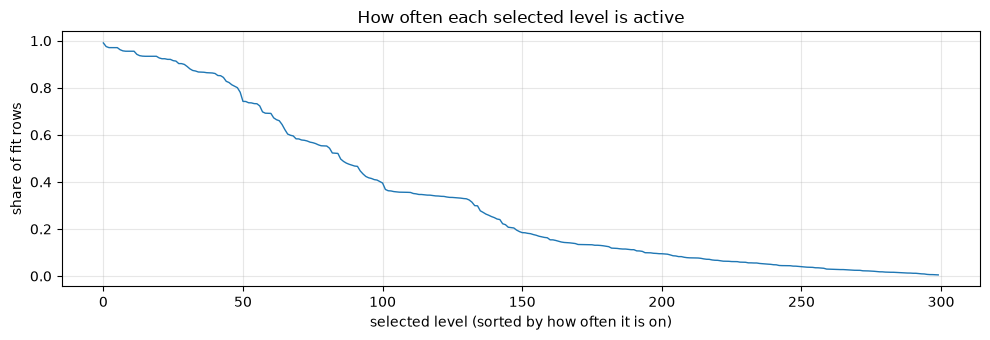

143 raw columns supply the 300 levels
most levels from: [(np.str_('ACTIN11_'), np.int64(3)), (np.str_('ACTIN21_'), np.int64(2)), (np.str_('ADDEPEV2'), np.int64(2)), (np.str_('ALCDAY5'), np.int64(1)), (np.str_('ARTHDIS2'), np.int64(3))]
top sources: [(np.str_('_AGEG5YR'), 10), (np.str_('DIABAGE2'), 6), (np.str_('_AGE80'), 6), (np.str_('BLDSUGAR'), 5), (np.str_('_AGE_G'), 5)]
MI range among selected: 0.0009 to 0.0245


In [10]:
header, _ = prep.ensure_header()
source_names = np.array([header[s] for s in state["sources"]])
# rate at which each selected level fires on the fit fold (0/1 before scale)
level_rate = (x_fit * state["scales"] + state["means"]).mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
eda.plot_selected_sources(axes[0], source_names, top=20,
                          title="Kept levels per raw column (top 20)")
axes[1].hist(state["mi"], bins=30, color="C1", alpha=0.85)
axes[1].set_xlabel("mutual information with MICHD (nats)")
axes[1].set_ylabel("number of levels")
axes[1].set_title("MI of the 300 selected levels")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

order = np.argsort(-level_rate)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(level_rate[order], lw=1)
ax.set_xlabel("selected level (sorted by how often it is on)")
ax.set_ylabel("share of fit rows")
ax.set_title("How often each selected level is active")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{len(np.unique(source_names))} raw columns supply the {len(source_names)} levels")
print("most levels from:", list(zip(*np.unique(source_names, return_counts=True)))[:5])
top = np.argsort(-np.unique(source_names, return_counts=True)[1])[:5]
names, counts = np.unique(source_names, return_counts=True)
print("top sources:", list(zip(names[top], counts[top].tolist())))
print(f"MI range among selected: {state['mi'].min():.4f} to {state['mi'].max():.4f}")


A few clinical items (age bands, employment, blood pressure, general health) each
contribute several levels. Many other columns contribute only one or two.
Most selected levels are rare indicators: the activity curve falls quickly.


### Level example: `PHYSHLTH`


In [11]:
min_count = int(round(cfg["min_level_share"] * fit_idx.size))
level = prep.fit_levels(
    x_train[fit_idx, prep.INDEX["PHYSHLTH"]], min_count, cfg["quantile_bins"]
)
print("own levels:", level["frequent"])
print("bin edges:", level["edges"], "missing:", level["missing"])
names, counts = np.unique([prep.HEADER[s] for s in state["sources"]], return_counts=True)
order = np.argsort(-counts)[:10]
print("sources with most kept levels:", list(zip(names[order], counts[order].tolist())))


own levels: [ 1.  2.  3.  4.  5.  7. 10. 14. 15. 20. 30. 77. 88.]
bin edges: [ 8. 16. 25. 28.] missing: False
sources with most kept levels: [(np.str_('_AGEG5YR'), 10), (np.str_('DIABAGE2'), 6), (np.str_('_AGE80'), 6), (np.str_('BLDSUGAR'), 5), (np.str_('_AGE_G'), 5), (np.str_('JOINPAIN'), 5), (np.str_('CHECKUP1'), 4), (np.str_('ARTHSOCL'), 4), (np.str_('FEETCHK'), 4), (np.str_('FC60_'), 4)]


## 3. Models

Three short fits on the same prepared matrix (bias column included), scored with an F1 cutoff on validation:

1. Course `logistic_regression` (full batch GD)
2. Mini batch SGD logistic (`model.fit_logistic_sgd`)
3. Course `ridge_regression`

The submitted model is the weighted FISTA logistic from `src/model.py` (section 3b).


In [12]:
tx_fit = np.c_[np.ones(len(x_fit)), x_fit]
tx_val = np.c_[np.ones(len(x_val)), x_val]
truth = np.where(y01[val_idx] == 1, 1, -1)
y_fit = y01[fit_idx]
w0 = np.zeros(tx_fit.shape[1])


def report(name, scores):
    threshold, _ = model.choose_threshold(scores, truth)
    metrics = model.classification_scores(scores, truth, threshold)
    print(
        f"{name:22s}  f1 {metrics['f1']:.4f}  prec {metrics['precision']:.4f}  "
        f"recall {metrics['recall']:.4f}  acc {metrics['accuracy']:.4f}  cut {threshold:.3f}"
    )


w_log, _ = logistic_regression(y_fit, tx_fit, w0.copy(), 50, 0.1)
report("logistic GD", tx_val @ w_log)

w_sgd = model.fit_logistic_sgd(tx_fit, y_fit, max_iters=2000, gamma=0.05, batch_size=256, rng=rng)
report("logistic SGD", tx_val @ w_sgd)

w_ridge, _ = ridge_regression(y_fit, tx_fit, 1e-4)
report("ridge", tx_val @ w_ridge)


Current iteration=0, loss=0.6931471805599453
logistic GD             f1 0.4212  prec 0.3306  recall 0.5803  acc 0.8592  cut -0.653
logistic SGD            f1 0.4286  prec 0.3448  recall 0.5662  acc 0.8667  cut -1.387
ridge                   f1 0.4188  prec 0.3327  recall 0.5651  acc 0.8615  cut 0.209


### 3b. Cross validation of the submitted model

Weighted FISTA logistic on the one hot MI matrix. Writes `pipeline_experiments.csv` and `permutation_importance.csv`.


In [13]:
experiments.main()

import csv
with open(experiments.IMPORTANCE_PATH, encoding="utf-8") as handle:
    rows = list(csv.DictReader(handle))[:10]
print("top permutation importance (fold 0):")
for row in rows:
    print(f"  {row['column']:12s}  pr_auc_drop {float(row['pr_auc_drop']):.4f}")


328135 rows, 321 raw columns, 8.83% positive, 5 folds
fold 0  pr_auc 0.3916  f1 0.4273  cols 300  83s
fold 1  pr_auc 0.3838  f1 0.4252  cols 300  65s
fold 2  pr_auc 0.3831  f1 0.4265  cols 300  64s
fold 3  pr_auc 0.3947  f1 0.4316  cols 300  58s
fold 4  pr_auc 0.3844  f1 0.4250  cols 300  37s
mean  pr_auc 0.3875  roc_auc 0.8606  f1 0.4271  prec 0.3550  recall 0.5374  cols 300
top permutation importance (fold 0):
  SEX           pr_auc_drop 0.0451
  CVDSTRK3      pr_auc_drop 0.0261
  GENHLTH       pr_auc_drop 0.0223
  TOLDHI2       pr_auc_drop 0.0177
  CHCCOPD1      pr_auc_drop 0.0129
  MAXVO2_       pr_auc_drop 0.0107
  PNEUVAC3      pr_auc_drop 0.0097
  _RFHLTH       pr_auc_drop 0.0082
  _AGE_G        pr_auc_drop 0.0060
  CHOLCHK       pr_auc_drop 0.0053


## 4. Final submission

`python run.py` runs the same call. Fit on 85% of labelled rows, choose the F1
cutoff on the other 15%, write `submissions/weighted_logistic.csv`.


In [14]:
experiments.submit()


tune f1 0.4346  prec 0.3649  recall 0.5373  threshold 1.7512  cols 300
test rows 109379  predicted positive 13.16%  wrote submissions\weighted_logistic.csv
